In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Read in the file containing all of the quantified runs

In [2]:
df = pd.read_csv('all_runs.csv')

In [3]:
df.head()

,date,filename,condition,#runs anterograde,#runs retrograde,movie length,runs/min,direction,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14
0,220819.0,S1_arches_post1_s1,wt,6,2,90,0.066667,anterograde,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,S1_arches_post1_s2,wt,6,1,90,0.066667,anterograde,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,S3_arches_post1_s4,wt,7,3,90,0.077778,anterograde,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,221006.0,S1_arches_post2_s2,wt,10,3,90,0.111111,anterograde,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,S2_arches_post2_s1_cell2,wt,11,3,90,0.122222,anterograde,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## The different conditions you can filter for

In [5]:
for item in df.condition.unique():
    print(item)

wt
TRAK2 kd
si control
TRAK1 kd
TRAK2 oe
TRAK1 oe
galactose O/N
galactose 48h


c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is depr

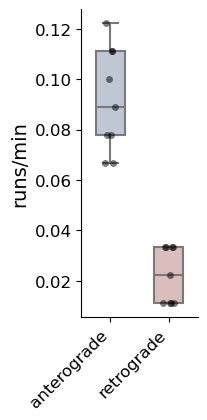

In [9]:
fig, ax = plt.subplots(figsize=(1.5, 4))

# You can filter for conditions using df[df.condition == 'condition name']
sns.stripplot(data=df[df.condition == 'wt'], x='direction', y='runs/min', color='black', alpha=0.5)
sns.boxplot(data=df[df.condition == 'wt'], x='direction', y='runs/min', palette='vlag', width=0.5)
plt.ylabel('runs/min', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(fontsize=12)
plt.xlabel('')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()
#plt.savefig('wt_runs.png', dpi=300, bbox_inches='tight')

Horizontal version of the plot

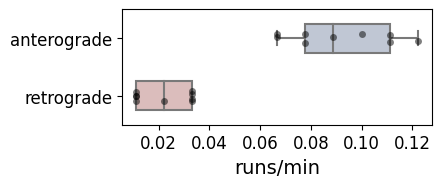

In [6]:
plt.figure(figsize=(4, 1.5))
sns.stripplot(data=df[df.condition == 'wt'], y='direction', x='runs/min', color='black', alpha=0.5)
sns.boxplot(data=df[df.condition == 'wt'], y='direction', x='runs/min', palette='vlag', width=0.5)
plt.xlabel('runs/min', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.ylabel('')

plt.show()
#plt.savefig('wt_runs_ho.png', dpi=300, bbox_inches='tight')

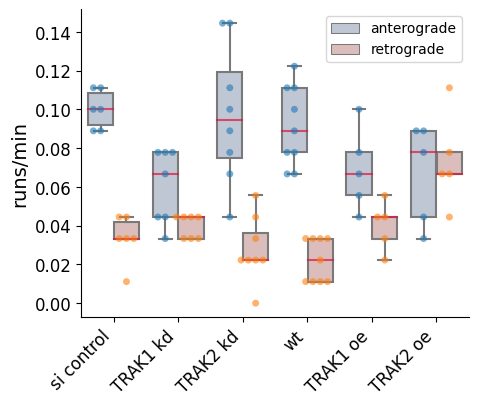

In [15]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.swarmplot(data=df.loc[~df.condition.isin(['galactose 48h', 'galactose O/N'])], x='condition', y='runs/min', hue='direction', alpha=0.6, dodge=True, legend=False, size=5, order=['si control', 'TRAK1 kd', 'TRAK2 kd', 'wt', 'TRAK1 oe', 'TRAK2 oe'])
sns.boxplot(data=df.loc[~df.condition.isin(['galactose 48h', 'galactose O/N'])], x='condition', y='runs/min', hue='direction', dodge=True, palette='vlag', medianprops={'color': 'crimson', 'alpha': 0.7}, showfliers=False, order=['si control', 'TRAK1 kd', 'TRAK2 kd', 'wt', 'TRAK1 oe', 'TRAK2 oe'])
#sns.violinplot(data=df, x='condition', y='runs/min', hue='direction')
plt.ylabel('runs/min', fontsize=14)
plt.yticks(fontsize=12)
plt.xlabel('')
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.legend(loc='upper right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()
#plt.savefig('all_runs_TRAK.png', dpi=300, bbox_inches='tight')

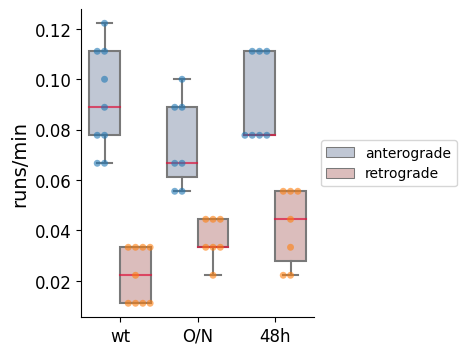

In [25]:
fig, ax = plt.subplots(figsize=(3, 4))
sns.swarmplot(data=df.loc[df.condition.isin(['wt', 'galactose 48h', 'galactose O/N'])], x='condition', y='runs/min', hue='direction', alpha=0.6, dodge=True, legend=False, size=5)
sns.boxplot(data=df.loc[df.condition.isin(['wt', 'galactose 48h', 'galactose O/N'])], x='condition', y='runs/min', hue='direction', dodge=True, palette='vlag', medianprops={'color': 'crimson', 'alpha': 0.7}, showfliers=False)
#sns.violinplot(data=df, x='condition', y='runs/min', hue='direction')
plt.ylabel('runs/min', fontsize=14)
plt.yticks(fontsize=12)
plt.xlabel('')
plt.xticks(['wt', 'galactose O/N', 'galactose 48h'], ['wt', 'O/N', '48h'], fontsize=12)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()
#plt.savefig('all_runs_gal.png', dpi=300, bbox_inches='tight')

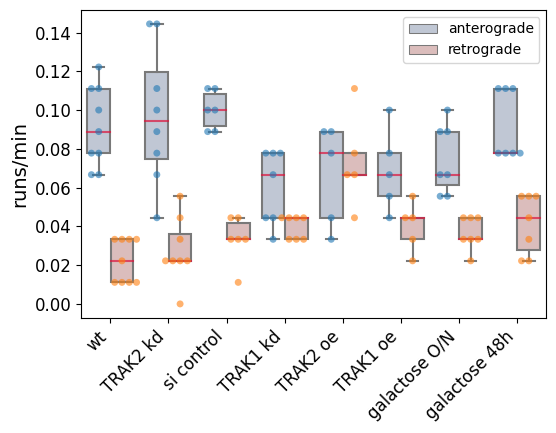

In [10]:
plt.figure(figsize=(6, 4))
sns.swarmplot(data=df, x='condition', y='runs/min', hue='direction', alpha=0.6, dodge=True, legend=False, size=5)
sns.boxplot(data=df, x='condition', y='runs/min', hue='direction', dodge=True, palette='vlag', medianprops={'color': 'crimson', 'alpha': 0.7}, showfliers=False)
#sns.violinplot(data=df, x='condition', y='runs/min', hue='direction')
plt.ylabel('runs/min', fontsize=14)
plt.yticks(fontsize=12)
plt.xlabel('')
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.legend(loc='upper right')

plt.show()

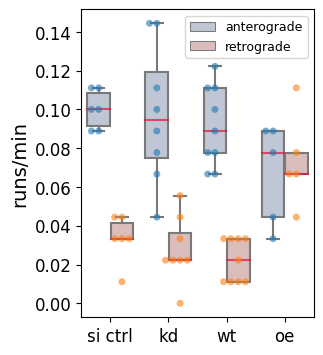

In [28]:
plt.figure(figsize=(3, 4))
sns.swarmplot(data=df.loc[df.condition.isin(['si control', 'TRAK2 kd', 'wt', 'TRAK2 oe'])], x='condition', y='runs/min', hue='direction', alpha=0.6, dodge=True, legend=False, size=5, order=['si control', 'TRAK2 kd', 'wt', 'TRAK2 oe'])
sns.boxplot(data=df.loc[df.condition.isin(['si control', 'TRAK2 kd', 'wt', 'TRAK2 oe'])], x='condition', y='runs/min', hue='direction', dodge=True, palette='vlag', medianprops={'color': 'crimson', 'alpha': 0.7}, showfliers=False, order=['si control', 'TRAK2 kd', 'wt', 'TRAK2 oe'])
#sns.violinplot(data=df, x='condition', y='runs/min', hue='direction')
plt.ylabel('runs/min', fontsize=14)
plt.yticks(fontsize=12)
plt.xlabel('')
plt.xticks(['si control', 'TRAK2 kd', 'wt', 'TRAK2 oe'], ['si ctrl', 'kd', 'wt', 'oe'], fontsize=12)
plt.legend(title='', fontsize=9)

plt.show()
#plt.savefig('all_runs_trak2.png', dpi=300, bbox_inches='tight')

In [30]:
df['ratio'] = df['#runs anterograde']/df['#runs retrograde']

(array([0, 1, 2, 3, 4, 5, 6, 7]),
 [Text(0, 0, 'si control'),
  Text(1, 0, 'TRAK2 kd'),
  Text(2, 0, 'TRAK1 kd'),
  Text(3, 0, 'wt'),
  Text(4, 0, 'TRAK2 oe'),
  Text(5, 0, 'TRAK1 oe'),
  Text(6, 0, 'galactose O/N'),
  Text(7, 0, 'galactose 48h')])

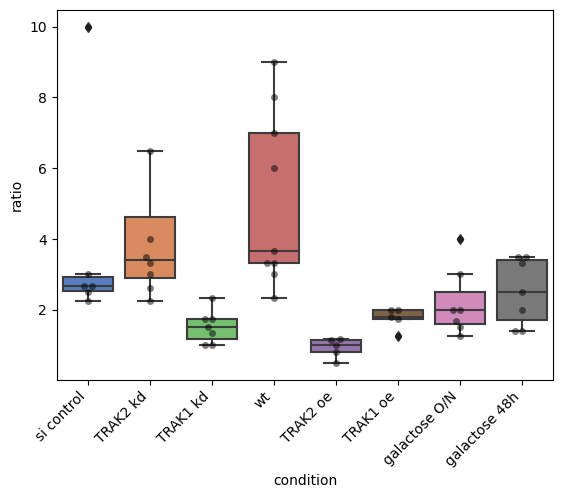

In [41]:
sns.boxplot(data=df[df.direction == 'anterograde'], x='condition', y='ratio', palette='muted', order=['si control', 'TRAK2 kd', 'TRAK1 kd', 'wt', 'TRAK2 oe', 'TRAK1 oe', 'galactose O/N', 'galactose 48h'])
sns.swarmplot(data=df[df.direction == 'anterograde'], x='condition', y='ratio', color='black', alpha=0.5, order=['si control', 'TRAK2 kd', 'TRAK1 kd', 'wt', 'TRAK2 oe', 'TRAK1 oe', 'galactose O/N', 'galactose 48h'])
plt.xticks(rotation=45, ha='right')